In [1]:
import pyspark
print(pyspark.__version__)

3.5.5


In [18]:
from pyspark.sql import SparkSession
import pandas as pd

spark = SparkSession.builder.getOrCreate()

In [31]:
df_train = (
    spark.read
    .format("csv")
    .option("header", True)
    .option("inferSchema", True)
    .option("sep", ",")
    .load("hdfs://localhost:9000/data/train/train.xls")
)

In [91]:
df_train = df_train.cache()
# Charger le dataframe en memoire pour optimiser les operations

25/05/10 17:08:56 WARN CacheManager: Asked to cache already cached data.


In [92]:
df_train.printSchema()

root
 |-- id: integer (nullable = true)
 |-- age: integer (nullable = true)
 |-- education: double (nullable = true)
 |-- sex: string (nullable = true)
 |-- is_smoking: string (nullable = true)
 |-- cigsPerDay: double (nullable = true)
 |-- BPMeds: double (nullable = true)
 |-- prevalentStroke: integer (nullable = true)
 |-- prevalentHyp: integer (nullable = true)
 |-- diabetes: integer (nullable = true)
 |-- totChol: double (nullable = true)
 |-- sysBP: double (nullable = true)
 |-- diaBP: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- heartRate: double (nullable = true)
 |-- glucose: double (nullable = true)
 |-- TenYearCHD: integer (nullable = true)



In [93]:
df_train.describe().toPandas()

,summary,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,count,3390,3390,3303,3390,3390,3368,3346,3390,3390,3390,3352,3390,3390,3376,3389,3086,3390
1,mean,1694.5,49.54218289085546,1.9709355131698456,None,None,9.069477434679335,0.029886431560071727,0.006489675516224189,0.3153392330383481,0.02566371681415929,237.07428400954655,132.60117994100295,82.8830383480826,25.794964454976267,75.97727943346119,82.08651976668827,0.15073746312684366
2,stddev,978.7530332009194,8.59287805192691,1.019080506396504,None,None,11.87907768177863,0.17029944333964098,0.08030854328226925,0.46471938562050297,0.1581533077833387,45.24742978889774,22.292029541520748,12.023581073495865,4.1154487553601475,11.971868473429424,24.244753474941987,0.3578455731418609
3,min,0,32,1.0,F,NO,0.0,0.0,0,0,0,107.0,83.5,48.0,15.96,45.0,40.0,0
4,max,3389,70,4.0,M,YES,70.0,1.0,1,1,1,696.0,295.0,142.5,56.8,143.0,394.0,1


In [94]:
from pyspark.sql.functions import col, sum as _sum, when, isnan

nulls = [
    _sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df_train.columns
]

null_counts_df = df_train.select(nulls)

count = df_train.count()


In [95]:
null_counts_df.toPandas()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,0,87,0,0,22,44,0,0,0,38,0,0,14,1,304,0


In [96]:
total_nulls = sum(
    r[c] for r in null_counts_df.collect() for c in r.asDict()
)
non_null = count-total_nulls

In [97]:
import matplotlib.pyplot as plt

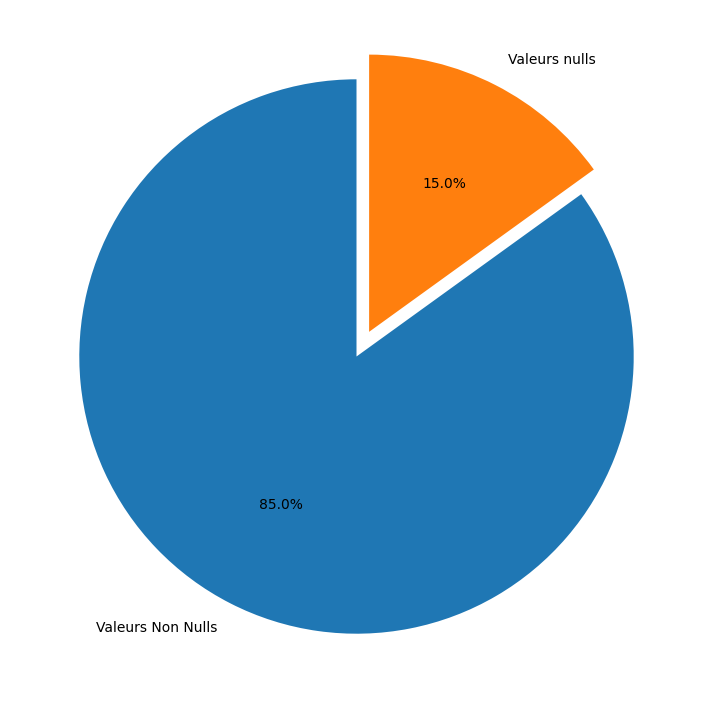

In [98]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.pie([non_null, total_nulls], explode=(0,0.1), labels=["Valeurs Non Nulls", "Valeurs nulls"], autopct='%1.1f%%', startangle=90)
plt.show()

In [99]:
null_counts_df.toPandas()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,0,87,0,0,22,44,0,0,0,38,0,0,14,1,304,0


In [131]:
# Les donnes manquant peut etre imputer(15% est imputable), donc j'ai decidee d'utiliser pyspark.ml.feature.Imputer

input_cols = ["education", "cigsPerDay", "BPMeds", "totChol", "BMI", "heartRate", "glucose"]
output_cols = ["education_imputed", "cigsPerDay_imputed", "BPMeds_imputed", "totChol_imputed", "BMI_imputed", "heartRate_imputed", "glucose_imputed"]

from pyspark.ml.feature import Imputer
imputer = Imputer()
imputer.setInputCols(input_cols)
imputer.setOutputCols(output_cols)
imputer.setRelativeError(0.01) # J'accept un peut d'erreur pour accelerer les calculs
imputer.setStrategy("median")
model = imputer.fit(df_train)

In [132]:
model.surrogateDF.show()

+---------+----------+------+-------+-----+---------+-------+
|education|cigsPerDay|BPMeds|totChol|  BMI|heartRate|glucose|
+---------+----------+------+-------+-----+---------+-------+
|      2.0|       0.0|   0.0|  233.0|25.36|     75.0|   78.0|
+---------+----------+------+-------+-----+---------+-------+



In [133]:
df_imputed = model.transform(df_train)

In [134]:
df_imputed.limit(5).toPandas()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,...,heartRate,glucose,TenYearCHD,education_imputed,cigsPerDay_imputed,BPMeds_imputed,totChol_imputed,BMI_imputed,heartRate_imputed,glucose_imputed
0,0,64,2.0,F,YES,3.0,0.0,0,0,0,...,90.0,80.0,1,2.0,3.0,0.0,221.0,25.36,90.0,80.0
1,1,36,4.0,M,NO,0.0,0.0,0,1,0,...,72.0,75.0,0,4.0,0.0,0.0,212.0,29.77,72.0,75.0
2,2,46,1.0,F,YES,10.0,0.0,0,0,0,...,88.0,94.0,0,1.0,10.0,0.0,250.0,20.35,88.0,94.0
3,3,50,1.0,M,YES,20.0,0.0,0,1,0,...,68.0,94.0,1,1.0,20.0,0.0,233.0,28.26,68.0,94.0
4,4,64,1.0,F,YES,30.0,0.0,0,0,0,...,70.0,77.0,0,1.0,30.0,0.0,241.0,26.42,70.0,77.0


In [135]:
df_imputed = df_imputed.drop(*input_cols)
df_imputed.cache()

DataFrame[id: int, age: int, sex: string, is_smoking: string, prevalentStroke: int, prevalentHyp: int, diabetes: int, sysBP: double, diaBP: double, TenYearCHD: int, education_imputed: double, cigsPerDay_imputed: double, BPMeds_imputed: double, totChol_imputed: double, BMI_imputed: double, heartRate_imputed: double, glucose_imputed: double]

In [136]:
df_imputed.limit(5).toPandas()

,id,age,sex,is_smoking,prevalentStroke,prevalentHyp,diabetes,sysBP,diaBP,TenYearCHD,education_imputed,cigsPerDay_imputed,BPMeds_imputed,totChol_imputed,BMI_imputed,heartRate_imputed,glucose_imputed
0,0,64,F,YES,0,0,0,148.0,85.0,1,2.0,3.0,0.0,221.0,25.36,90.0,80.0
1,1,36,M,NO,0,1,0,168.0,98.0,0,4.0,0.0,0.0,212.0,29.77,72.0,75.0
2,2,46,F,YES,0,0,0,116.0,71.0,0,1.0,10.0,0.0,250.0,20.35,88.0,94.0
3,3,50,M,YES,0,1,0,158.0,88.0,1,1.0,20.0,0.0,233.0,28.26,68.0,94.0
4,4,64,F,YES,0,0,0,136.5,85.0,0,1.0,30.0,0.0,241.0,26.42,70.0,77.0
